In [1]:
from pathlib import Path
import pandas as pd 


RAIZ = Path.cwd().parent if  Path.cwd().name == "notebooks" else Path.pwd()
CRUDOS = RAIZ / "data" / "raw"


print(RAIZ)
print(sorted(p.name for p in CRUDOS.glob("*.csv")))

/run/media/massinger/Vainas/Proyectos/bogotá_calidad_aire
['carvajal_pm25.csv', 'guaymaral_pm25.csv', 'kennedy_pm25.csv', 'lasferias_pm25.csv', 'minambiente_pm25.csv', 'paranda_pm25.csv', 'scristobal_pm25.csv', 'suba_pm25.csv', 'tunal_pm25.csv', 'usaquen_pm25.csv']


In [2]:
series = {} 

for archivo in sorted(CRUDOS.glob("*_pm25.csv")):
    nombre = archivo.stem.replace("_pm25", "")
    d = pd.read_csv(archivo)
    d["fecha"] = pd.to_datetime(d["Fecha inicial"])
    series[nombre] = d.set_index("fecha")["PM2.5"].sort_index()

pm = pd.DataFrame(series).asfreq("D")


print(pm.shape)
pm.head()

(4626, 10)


,carvajal,guaymaral,kennedy,lasferias,minambiente,paranda,scristobal,suba,tunal,usaquen
fecha,,,,,,,,,,
2014-01-01,13.062500,NaN,27.090278,11.815686,NaN,NaN,NaN,NaN,NaN,4.230588
2014-01-02,20.551389,NaN,22.731481,10.760833,NaN,NaN,NaN,NaN,NaN,9.142667
2014-01-03,23.673611,NaN,16.291667,9.306481,NaN,NaN,NaN,NaN,NaN,4.644917
2014-01-04,21.118056,NaN,22.256944,8.987500,NaN,NaN,NaN,NaN,NaN,5.160312
2014-01-05,17.451389,NaN,24.250000,10.608333,NaN,NaN,NaN,NaN,NaN,7.972879


In [3]:
print("Días con dato por estación: ")
print(pm.notna().sum())

print("\n Desde cuándo mide cada una: ")
print(pm.apply(lambda c: c.first_valid_index()))


print("\n Cuántas estaciones reportan ese día: ")
print(pm.notna().sum(axis=1).value_counts().sort_index())



Días con dato por estación: 
carvajal       3739
guaymaral      4152
kennedy        4380
lasferias      4425
minambiente    4346
paranda        3377
scristobal     4232
suba           4290
tunal          4147
usaquen        4236
dtype: int64

 Desde cuándo mide cada una: 
carvajal      2014-01-01
guaymaral     2014-10-15
kennedy       2014-01-01
lasferias     2014-01-01
minambiente   2014-03-26
paranda       2016-09-21
scristobal    2014-05-02
suba          2014-03-07
tunal         2015-01-01
usaquen       2014-01-01
dtype: datetime64[us]

 Cuántas estaciones reportan ese día: 
0        9
1        6
2       11
3       27
4       62
5       59
6      114
7      251
8      559
9     1521
10    2007
Name: count, dtype: int64


In [4]:
print("Última fecha de cada estación:")
print(pm.apply(lambda c: c.last_valid_index()))

pm = pm.loc["2017-01-01":"2026-07-31"]

n_estaciones = pm.notna().sum(axis=1)
validos = n_estaciones >= 8

print("\nDías en el periodo:", len(pm))
print("Días con al menos 8 estaciones:", validos.sum())
print("Porcentaje válido:", round(100 * validos.mean(), 1), "%")

Última fecha de cada estación:
carvajal      2026-08-31
guaymaral     2026-08-31
kennedy       2026-07-31
lasferias     2026-08-31
minambiente   2026-08-31
paranda       2026-08-31
scristobal    2026-08-31
suba          2026-08-31
tunal         2026-08-31
usaquen       2026-08-31
dtype: datetime64[us]

Días en el periodo: 3499
Días con al menos 8 estaciones: 3376
Porcentaje válido: 96.5 %


In [5]:
PROCESADOS = RAIZ / "data" / "processed"
PROCESADOS.mkdir(parents=True, exist_ok=True)

pm_limpio = pm[validos]
pm_limpio.to_csv(PROCESADOS / "pm25_diario_2017_2026.csv")

print(pm_limpio.shape)

(3376, 10)


In [7]:
from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt 


RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pm = pd.read_csv(
    RAIZ / "data" / "processed" /"pm25_diario_2017_2026.csv", 
    index_col="fecha", 
    parse_dates=True,
)


print(pm.shape)
pm.head()

(3376, 10)


,carvajal,guaymaral,kennedy,lasferias,minambiente,paranda,scristobal,suba,tunal,usaquen
fecha,,,,,,,,,,
2017-01-01,13.460870,7.666667,NaN,NaN,4.600000,5.619048,9.112500,12.260870,13.454545,6.857143
2017-01-02,13.195652,5.526316,NaN,NaN,4.400000,6.658333,7.594118,10.083333,26.166667,8.166667
2017-01-03,22.716667,14.227273,15.333333,16.500000,10.714286,16.816667,7.500000,18.625000,13.166667,8.666667
2017-01-04,24.970833,13.125000,22.125000,14.687500,18.666667,17.395833,10.695833,20.208333,18.916667,15.833333
2017-01-05,28.116667,16.791667,26.083333,17.704167,24.916667,24.245833,12.270833,22.916667,21.791667,15.708333


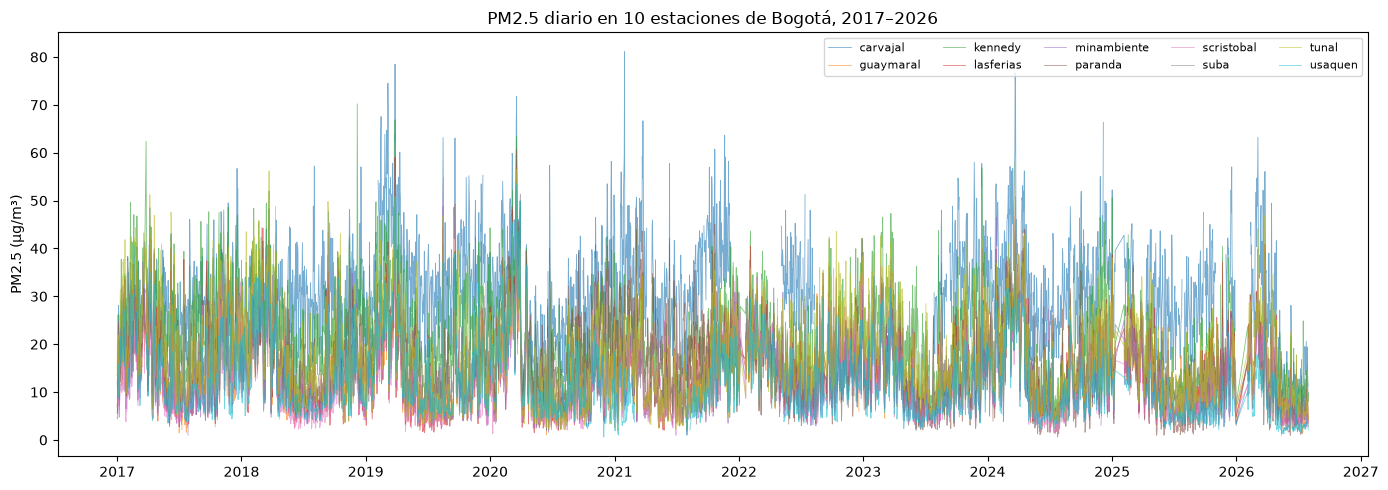

In [8]:
fig, ax = plt.subplots(figsize=(14, 5))

for estacion in pm.columns:
    ax.plot(pm.index, pm[estacion], linewidth=0.6, alpha=0.6, label=estacion)

ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("PM2.5 diario en 10 estaciones de Bogotá, 2017–2026")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
comun = pm.mean(axis=1)          # promedio de las 10 estaciones, día a día
anomalias = pm.sub(comun, axis=0)  # cada estación menos ese promedio
dispersion = pm.std(axis=1)        # qué tan dispersas están las estaciones ese día

resumen = pd.DataFrame({
    "comun": comun,
    "dispersion": dispersion,
    "razon": dispersion / comun,
})

print(resumen.describe())

             comun   dispersion        razon
count  3376.000000  3376.000000  3376.000000
mean     16.471920     6.518431     0.451435
std       7.348603     2.459104     0.202519
min       3.402616     1.088597     0.059958
25%      10.900043     4.673323     0.290105
50%      15.310092     6.456750     0.424330
75%      20.860121     8.081495     0.595676
max      55.824167    21.314534     1.272507


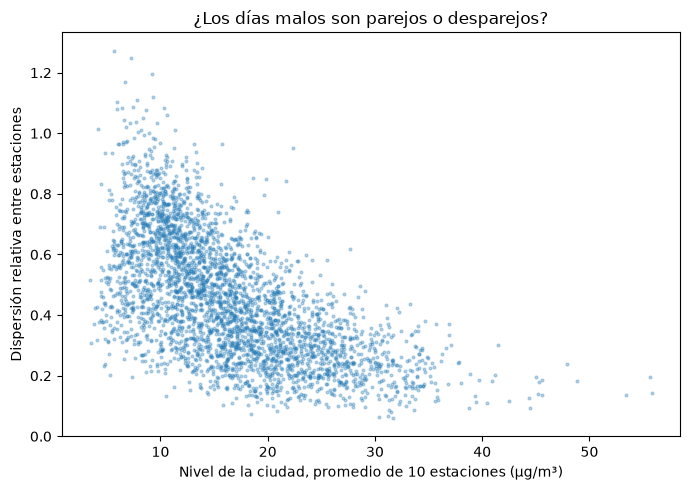

Correlación: -0.617


In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(resumen["comun"], resumen["razon"], s=4, alpha=0.3)
ax.set_xlabel("Nivel de la ciudad, promedio de 10 estaciones (µg/m³)")
ax.set_ylabel("Dispersión relativa entre estaciones")
ax.set_title("¿Los días malos son parejos o desparejos?")
plt.tight_layout()
plt.show()

print("Correlación:", resumen["comun"].corr(resumen["razon"]).round(3))

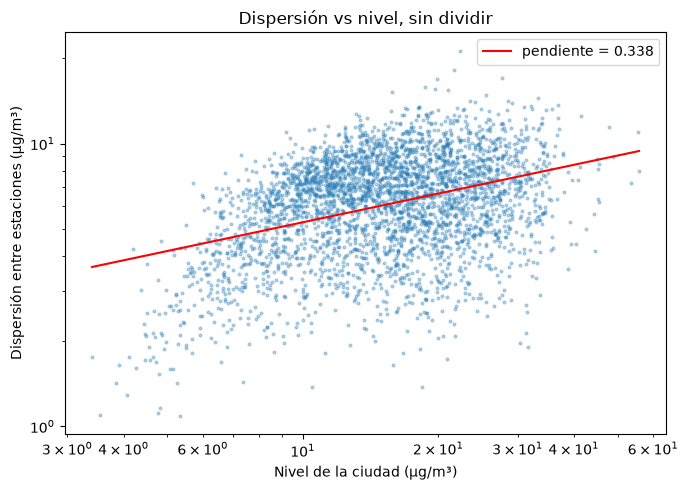

In [11]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(resumen["comun"], resumen["dispersion"], s=4, alpha=0.3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Nivel de la ciudad (µg/m³)")
ax.set_ylabel("Dispersión entre estaciones (µg/m³)")
ax.set_title("Dispersión vs nivel, sin dividir")

beta, log_a = np.polyfit(np.log(resumen["comun"]), np.log(resumen["dispersion"]), 1)
x = np.linspace(resumen["comun"].min(), resumen["comun"].max(), 100)
ax.plot(x, np.exp(log_a) * x**beta, "r-", label=f"pendiente = {beta:.3f}")
ax.legend()
plt.tight_layout(); plt.show()

In [12]:
rng = np.random.default_rng(42)
logx = np.log(resumen["comun"].values)
logy = np.log(resumen["dispersion"].values)
n = len(logx)

pendientes = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    b, _ = np.polyfit(logx[idx], logy[idx], 1)
    pendientes.append(b)

pendientes = np.array(pendientes)
print("Pendiente:", round(beta, 3))
print("Intervalo 95%:", np.percentile(pendientes, [2.5, 97.5]).round(3))

Pendiente: 0.338
Intervalo 95%: [0.306 0.371]


In [13]:
bloque = 30  # días por bloque
n_bloques = n // bloque

pendientes_b = []
for _ in range(1000):
    inicios = rng.integers(0, n - bloque, n_bloques)
    idx = np.concatenate([np.arange(i, i + bloque) for i in inicios])
    b, _ = np.polyfit(logx[idx], logy[idx], 1)
    pendientes_b.append(b)

pendientes_b = np.array(pendientes_b)
print("Intervalo 95% por bloques:", np.percentile(pendientes_b, [2.5, 97.5]).round(3))

Intervalo 95% por bloques: [0.242 0.413]
